In [1]:
import sys
from pathlib import Path

current_path = Path.cwd()

if (current_path / "src").exists():
    PROJECT_ROOT = current_path
elif (current_path.parent / "src").exists():
    PROJECT_ROOT = current_path.parent
else:
    raise FileNotFoundError("No se encontró la carpeta src.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /Users/macbook/Usach/TesisxD/cosmo_singularities


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df_all = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "phantom_models_dataset.csv"
)

df_all.head()

,model_name,A,nu,alpha,rho0,a0,t0,singularity_type,singular_time,valid_solution,...,a_max,H_initial,H_final,H_max,P_initial,P_final,P_abs_max,Hdot_initial,Hdot_final,Hdot_max
0,phantom_q0,0.5,-1.0,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,35129.050795,0.408248,1.369412,1.369412,-1.500000,-5.714740,5.714740,0.500000,0.044438,0.500000
1,phantom_q0,0.5,-1.0,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,54376.907471,0.577350,1.391178,1.391178,-1.500000,-5.892241,5.892241,0.250000,0.043058,0.250000
2,phantom_q0,0.5,-1.0,NaN,2.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,147751.395138,0.816497,1.449319,1.449319,-2.250000,-6.380921,6.380921,0.125000,0.039673,0.125000
3,phantom_q0,0.5,-0.5,NaN,0.5,1.0,0.0,Type II / Sudden singularity,NaN,True,...,191912.682973,0.408248,1.747403,1.747403,-1.207107,-9.325456,9.325456,0.353553,0.082601,0.353553
4,phantom_q0,0.5,-0.5,NaN,1.0,1.0,0.0,Type II / Sudden singularity,NaN,True,...,400309.791321,0.577350,1.794459,1.794459,-1.500000,-9.821124,9.821124,0.250000,0.080435,0.250000


In [4]:
df_all.info()
print("--------------------------------")
df_all["valid_solution"].value_counts()
print("--------------------------------")
df_all.groupby(["model_name", "singularity_type"]).size()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 504 entries, 0 to 503
Data columns (total 28 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   model_name        504 non-null    object 
 1   A                 504 non-null    float64
 2   nu                504 non-null    float64
 3   alpha             432 non-null    float64
 4   rho0              504 non-null    float64
 5   a0                504 non-null    float64
 6   t0                504 non-null    float64
 7   singularity_type  504 non-null    object 
 8   singular_time     216 non-null    float64
 9   valid_solution    504 non-null    bool   
 10  error_message     76 non-null     object 
 11  t_eval_min        428 non-null    float64
 12  t_eval_max        428 non-null    float64
 13  rho_initial       428 non-null    float64
 14  rho_final         428 non-null    float64
 15  rho_max           428 non-null    float64
 16  a_initial         428 non-null    float64
 1

model_name          singularity_type            
phantom_q0          Ambiguous                        42
                    Non singular                      3
                    Type II / Sudden singularity     18
                    Type IV                           9
phantom_qalpha_rho  Ambiguous                        34
                    Non singular                     20
                    Type I / Big Rip                108
                    Type II / Sudden singularity    108
                    Type III                        108
                    Type IV                          54
dtype: int64

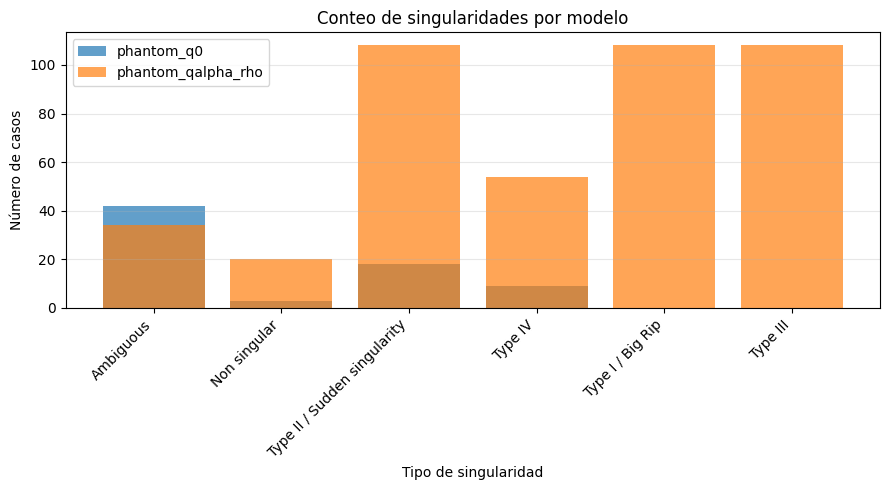

In [5]:
counts = (
    df_all
    .groupby(["model_name", "singularity_type"])
    .size()
    .reset_index(name="count")
)

plt.figure(figsize=(9, 5))

for model_name in counts["model_name"].unique():
    subset = counts[counts["model_name"] == model_name]

    plt.bar(
        subset["singularity_type"],
        subset["count"],
        alpha=0.7,
        label=model_name,
    )

plt.xlabel("Tipo de singularidad")
plt.ylabel("Número de casos")
plt.title("Conteo de singularidades por modelo")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
df_valid = df_all[df_all["valid_solution"]].copy()

df_alpha = df_valid[
    df_valid["model_name"] == "phantom_qalpha_rho"
].copy()

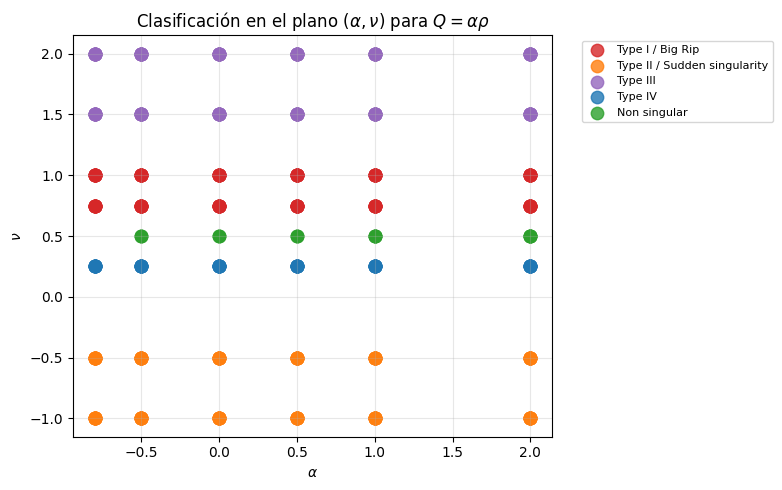

In [7]:
color_map = {
    "Type I / Big Rip": "tab:red",
    "Type II / Sudden singularity": "tab:orange",
    "Type III": "tab:purple",
    "Type IV": "tab:blue",
    "Non singular": "tab:green",
    "Ambiguous": "tab:gray",
}

plt.figure(figsize=(8, 5))

for singularity_type, color in color_map.items():
    subset = df_alpha[df_alpha["singularity_type"] == singularity_type]

    if len(subset) == 0:
        continue

    plt.scatter(
        subset["alpha"],
        subset["nu"],
        s=80,
        alpha=0.8,
        color=color,
        label=singularity_type,
    )

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$\nu$")
plt.title(r"Clasificación en el plano $(\alpha,\nu)$ para $Q=\alpha\rho$")
plt.legend(fontsize=8, bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

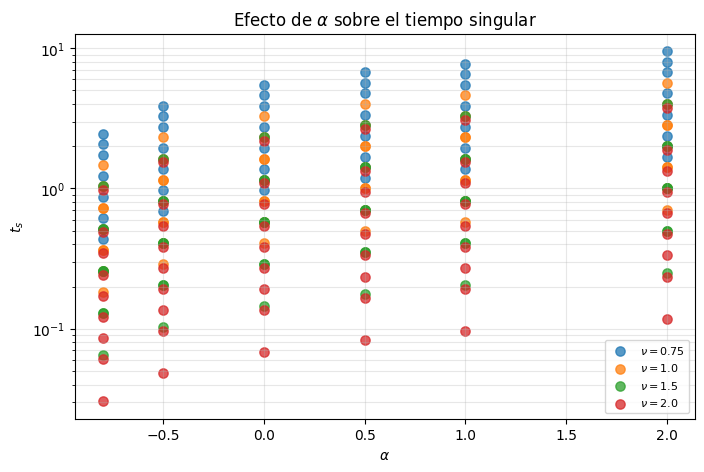

In [8]:
df_alpha_ts = df_alpha[np.isfinite(df_alpha["singular_time"])].copy()

plt.figure(figsize=(8, 5))

for nu in sorted(df_alpha_ts["nu"].unique()):
    subset = df_alpha_ts[df_alpha_ts["nu"] == nu]

    plt.scatter(
        subset["alpha"],
        subset["singular_time"],
        s=45,
        alpha=0.75,
        label=rf"$\nu={nu}$",
    )

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$t_s$")
plt.yscale("log")
plt.title(r"Efecto de $\alpha$ sobre el tiempo singular")
plt.legend(fontsize=8)
plt.grid(True, which="both", alpha=0.3)
plt.show()